## Analysing the extracted data to be used to fit the transfer function of a neuron with N synaptic channels.

#### Ilaria Carannante
mailto: ilariac@kth.se
###### KTH, Stockholm, Sweden
###### NeuroPSI, ICN, Saclay, France

In this notebook we analyse the data extracted with *TF_data_extraction_neuron_4_inputs.py* before fitting the transfer function. Compared with the two-channel case (*Analysing_extracted_data.ipynb*), the input space has one dimension per synaptic channel, so the 2D plots are drawn on slices (two channels varied, the others held fixed), and a few overview plots cover the full input space.

In [1]:
#%matplotlib widget
import matplotlib.pyplot as plt

In [2]:
import sys
import os
import json

# Adding the project folder to sys.path
cwd = os.getcwd()
parent_dir = os.path.abspath(os.path.join(cwd, '..', '..',))
sys.path.append(parent_dir)
# We do this so that we can directly import files in the utils folder

In [3]:
from utils.Plots_helper import *

In [4]:
# Setting file saving
figs = []
fig_path = os.path.join('figures')
isExist = os.path.exists(fig_path)
if not isExist:
   os.makedirs(fig_path)
   print('The directory "figures" is created.')

def save_figs(fig_path, name, figs):
    pdf_file_path = os.path.join(fig_path, name + '-figs.pdf')
    with PdfPages(pdf_file_path) as ofile:
        for fig in figs:
            ofile.savefig(fig) 

In [5]:
neuron_model = 'neuron_4_inputs'
simulation_folder = os.path.join('simulations', f'TF_{neuron_model}_delay_v2')

fig_name = f'Analysing_TF_data_extraction_{neuron_model}'

### Loading the data

In [6]:
# --- Load the data ---
df = pd.read_csv(
    os.path.join(simulation_folder, f'TF_data_{neuron_model}.dat'),
    sep=r'\s+',
    header=0
)

# --- Load the metadata written by the extraction script (channel parameters, protocol) ---
with open(os.path.join(simulation_folder, f'TF_data_{neuron_model}_meta.json'), 'r') as fh:
    meta = json.load(fh)

channels = list(meta['channels'])
ch_info = tf_channel_info(meta)

'''
for k in channels:
    c = meta['channels'][k]
    print(f"{ch_info[k]['short']}: E = {c['E']} mV, Q = {c['Q']} nS, tau = {c['tau']} ms, "
          f"K = {c['K']:.1f}, background = {c['background_freq']} Hz")
'''

'\nfor k in channels:\n    c = meta[\'channels\'][k]\n    print(f"{ch_info[k][\'short\']}: E = {c[\'E\']} mV, Q = {c[\'Q\']} nS, tau = {c[\'tau\']} ms, "\n          f"K = {c[\'K\']:.1f}, background = {c[\'background_freq\']} Hz")\n'

In [7]:
grid_vals, is_grid = tf_grid_values(df, channels)
print(f'Number of simulated input points: {len(df)} -- sampling: {meta["sampling"].get("mode", "grid")} -- full grid: {is_grid}')
print('These are the values in Hz of the Poissonian stimulation on each channel:')
for k in channels:
    print(f'  ch {k}: {grid_vals[k].tolist()}')

Number of simulated input points: 256 -- sampling: grid -- full grid: True
These are the values in Hz of the Poissonian stimulation on each channel:
  ch 1: [0, 10, 20, 30]
  ch 2: [0, 10, 20, 30]
  ch 3: [0, 10, 20, 30]
  ch 4: [0, 10, 20, 30]


In [8]:
# Quick numerical summary of the output
df[['avg_f_out', 'std_f_out']].describe()

,avg_f_out,std_f_out
count,256.000000,256.000000
mean,10.595312,0.898104
std,12.455004,0.651270
min,0.000000,0.000000
25%,0.075000,0.339042
50%,6.050000,1.016890
75%,17.575000,1.349280
max,48.800000,2.587900


### Overview of the full input space
Distribution of the output rate over all simulated points. A large fraction of silent points, or a maximum far above the rates of interest, suggests that the per-channel ranges in the sweep config should be adjusted before the full run.

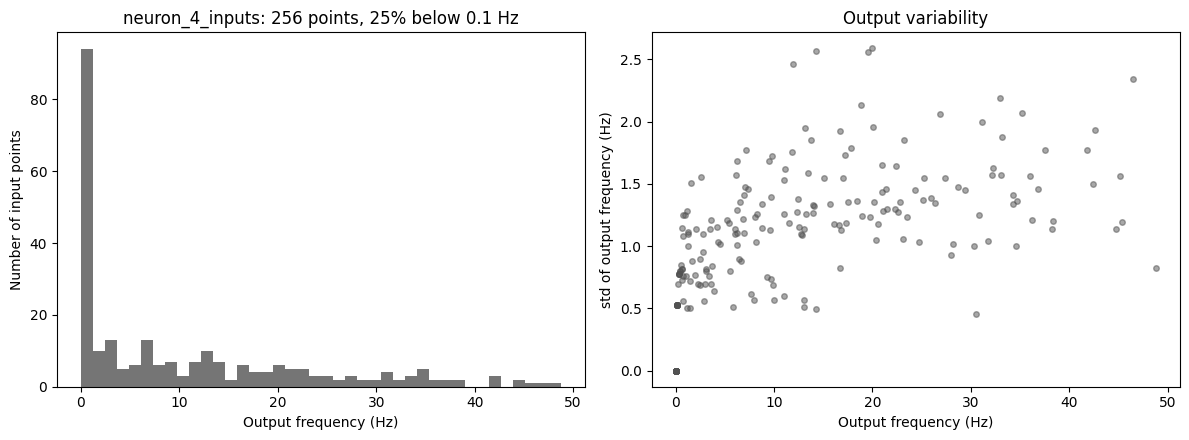

In [9]:
fig = plot_TF_output_summary(df, neuron_model=neuron_model)
figs.append(fig)

Output rate against each channel, all other channels pooled (mean in colour: green/circles excitatory, red/squares inhibitory).

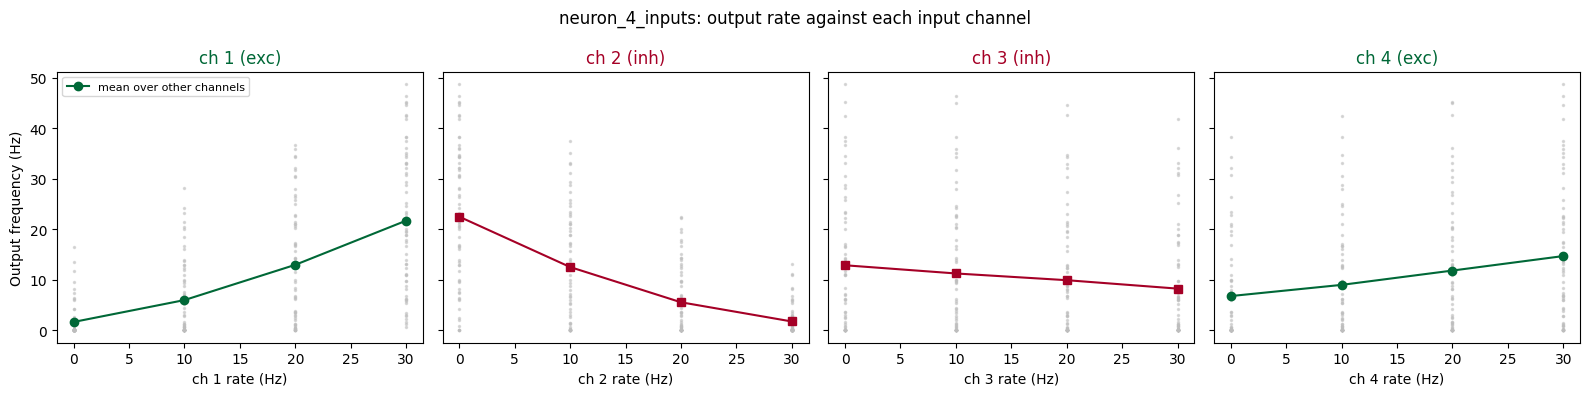

In [10]:
fig = plot_TF_main_effects(df, ch_info, neuron_model=neuron_model)
figs.append(fig)

### Plotting the firing frequency as function of the Poissonian input
The remaining plots require gridded data (they slice the table at grid values).

In [11]:
assert is_grid, 'Slice plots need grid sampling; for LHS data use the overview plots above.'

# Main excitatory drive: the excitatory channel with the largest number of inputs K
exc_chs = [k for k in channels if ch_info[k]['kind'] == 'exc']
inh_chs = [k for k in channels if ch_info[k]['kind'] == 'inh']
x_ch = max(exc_chs, key=lambda k: meta['channels'][k]['K'])
y_ch = max(inh_chs, key=lambda k: meta['channels'][k]['K'])
others = [k for k in channels if k not in (x_ch, y_ch)]

# Reference point for the slices: lowest grid value on every channel except the main excitatory drive
reference = {k: float(grid_vals[k][0]) for k in channels}
reference[x_ch] = float(grid_vals[x_ch][len(grid_vals[x_ch]) // 2])
print(f'x axis: ch {x_ch}, y axis: ch {y_ch}, other channels: {others}')
print(f'reference point (Hz): {reference}')

x axis: ch 1, y axis: ch 2, other channels: ['3', '4']
reference point (Hz): {'1': 20.0, '2': 0.0, '3': 0.0, '4': 0.0}


#### One channel at a time
Each panel varies one channel with the others at the reference point; one curve per value of the main excitatory drive.

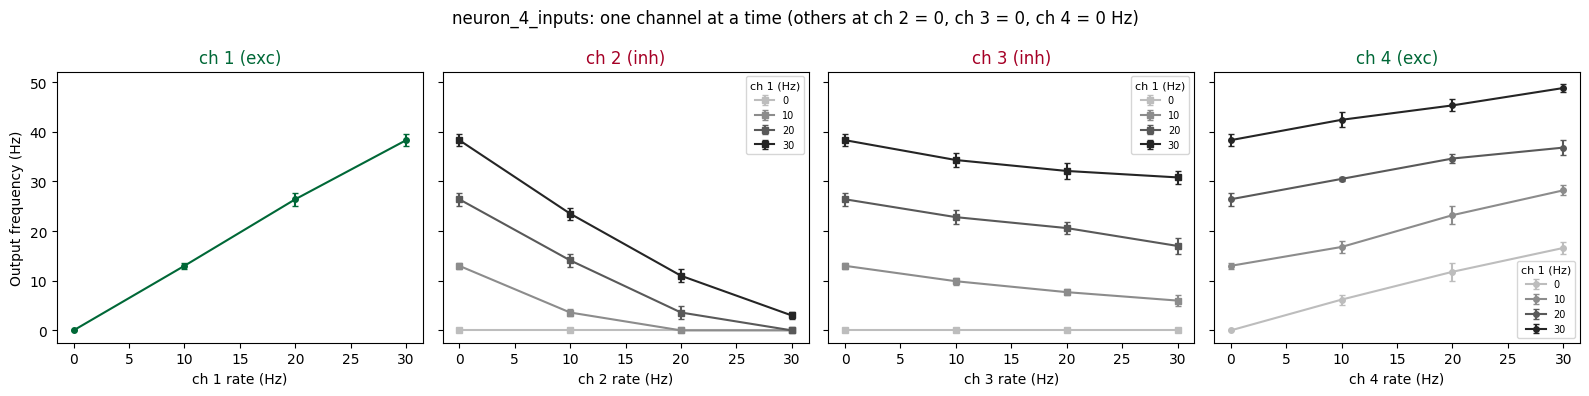

In [12]:
fig = plot_TF_channel_curves(df, ch_info, neuron_model=neuron_model, reference=reference, hue_ch=x_ch)
figs.append(fig)

#### All channels together
Each panel is an output-rate map over the main excitatory (x) and inhibitory (y) channels; panels are arranged by the two remaining channels. One shared colour scale.

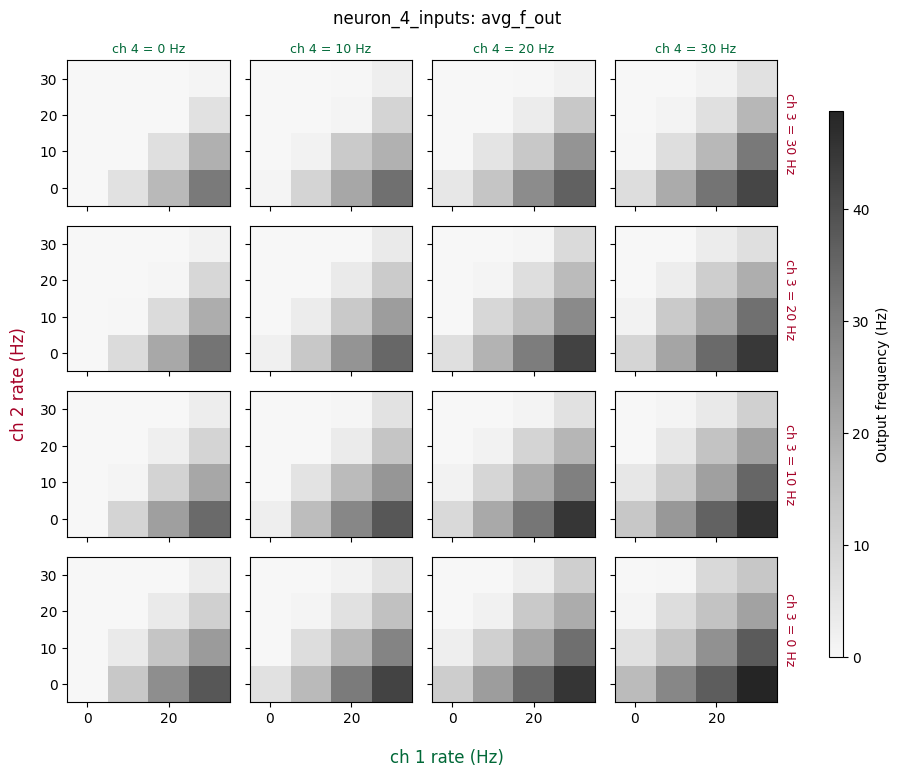

In [13]:
fig = plot_TF_slice_grid(df, ch_info, neuron_model=neuron_model,
                         x_ch=x_ch, y_ch=y_ch,
                         row_ch=others[0] if len(others) > 0 else None,
                         col_ch=others[1] if len(others) > 1 else None,
                         fixed={k: reference[k] for k in others[2:]})
figs.append(fig)

#### Two-channel slice
The plots used for the FS and RS neurons, on the (x, y) slice with the other channels at the reference point. Change `fixed` to inspect other slices.

In [14]:
fixed = {k: reference[k] for k in others}
suffix = ' | ' + ', '.join(f'ch {k} = {v:g} Hz' for k, v in fixed.items())

# Slicing the data
x_s, y_s, df_slice_array = tf_slice_2d(df, x_ch, y_ch, fixed, value_col='avg_f_out')
_, _, df_std_slice_array = tf_slice_2d(df, x_ch, y_ch, fixed, value_col='std_f_out')

labels = dict(x_label=ch_info[x_ch]['label'], y_label=ch_info[y_ch]['label'], title_suffix=suffix)

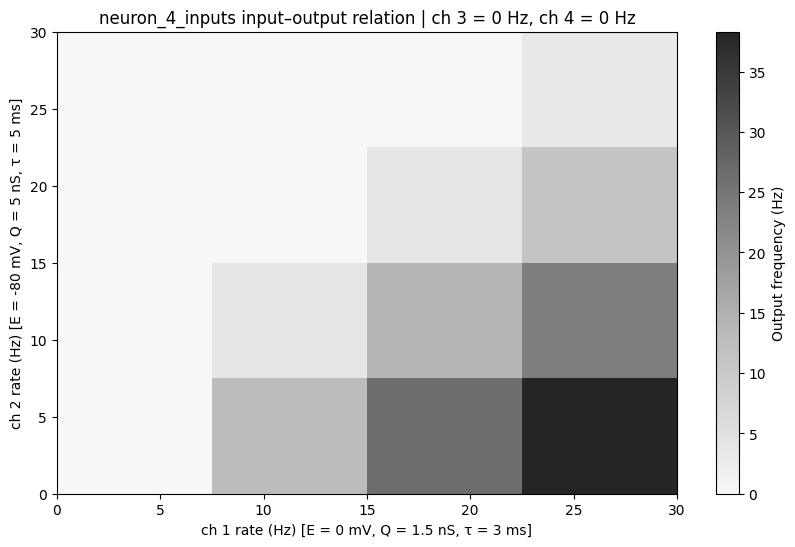

In [15]:
fig = heatmap_InOut(x_s, y_s, df_slice_array, neuron_type=neuron_model, **labels)
figs.append(fig)

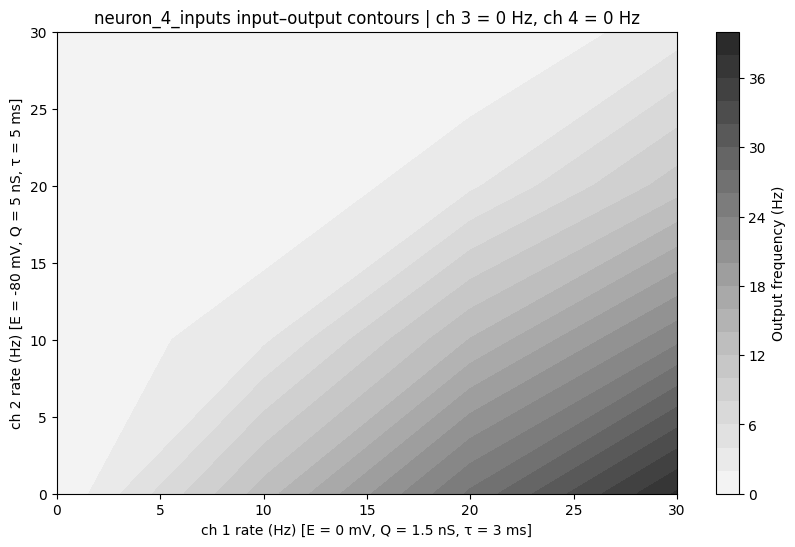

In [16]:
fig = plot_contours(x_s, y_s, df_slice_array, neuron_type=neuron_model, **labels)
figs.append(fig)

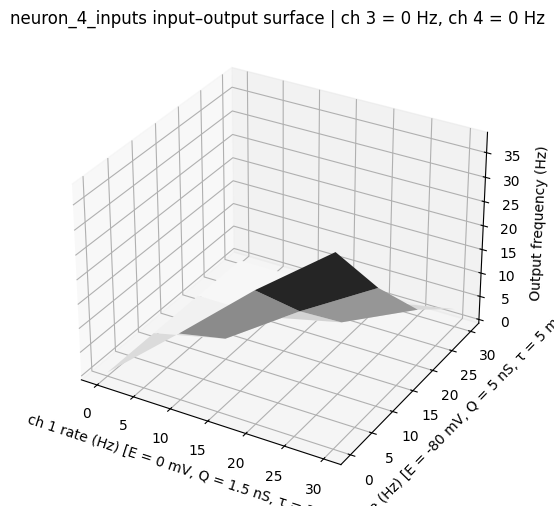

In [17]:
fig = mesh_3d(x_s, y_s, df_slice_array, neuron_type=neuron_model, **labels)
figs.append(fig)

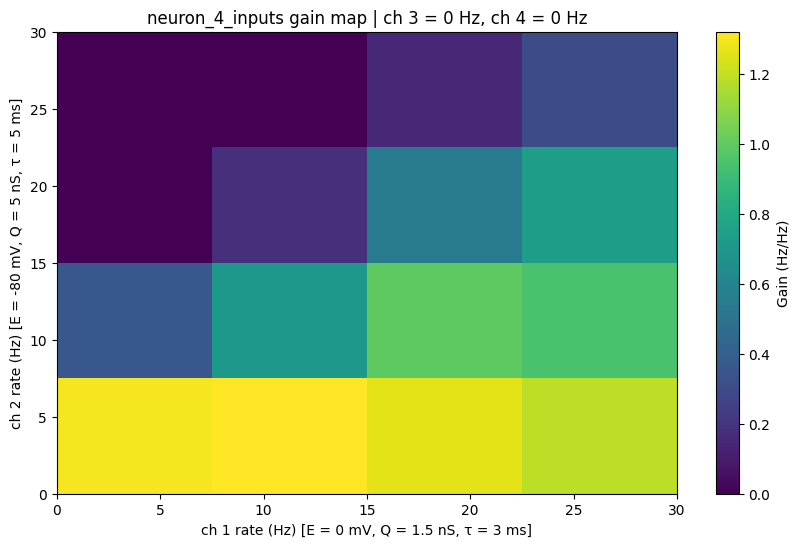

In [18]:
fig = plot_gain(x_s, y_s, df_slice_array, neuron_type=neuron_model, **labels)
figs.append(fig)

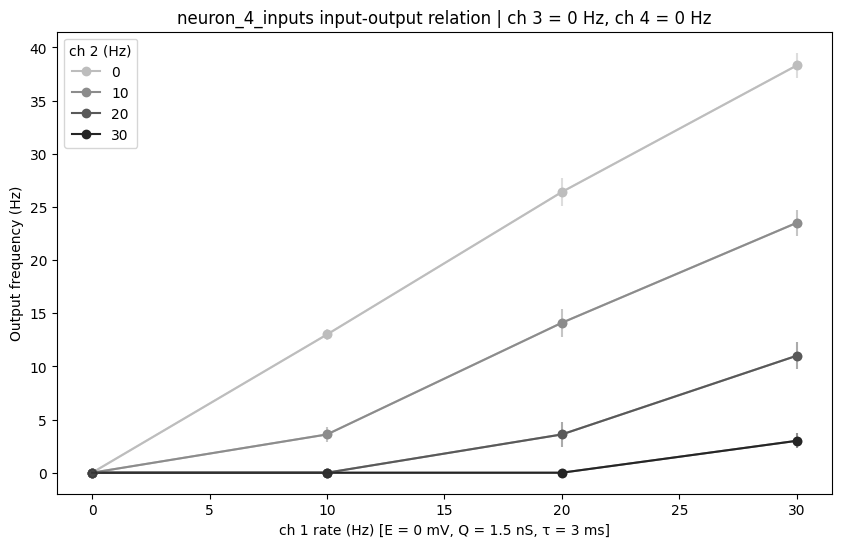

In [19]:
fig = plot_InOut_relation(x_s, y_s, df_slice_array, df_std_slice_array, neuron_type=neuron_model,
                          x_label=ch_info[x_ch]['label'], legend_title=f'ch {y_ch} (Hz)',
                          label_every=1, title_suffix=suffix)
figs.append(fig)

In [20]:
save_figs(fig_path, fig_name, figs)